# 02 — Preprocessing and PCA: UCI HAR

**Goal:** turn the raw windows into the inputs the models will use, and decide how many principal components to keep.

- Every step is **fit on the training set only** and then applied unchanged to the test set (and later, refit inside each CV fold). No decision in this notebook looks at test labels or test statistics.
- The implementation is in `src/preprocess.py` (my code: the `TODO`s). This notebook calls it, checks each piece against scikit-learn, and records the decisions.
- Carried over from `01_eda`: no missing values, all values in [-1, 1], 21 copied columns, feature standard deviations 0.04–0.75, heavy redundancy (391 of 561 features have a partner at |r| > 0.95).
- ✍️ cells are for my decisions and interpretation.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append("../src")
from har_data import load_har
import plot_style as ps
from preprocess import remap_labels, DropDuplicateColumns, Standardizer, PCA

ps.apply_style()
save = ps.saver("../figures/preprocessing")

d = load_har()
ACT = d.activities                      # {1: 'WALKING', ...}
ORDER = [ACT[i] for i in sorted(ACT)]   # label order 1..6
DYNAMIC = ORDER[:3]                     # the three walking activities
print(f"train {d.X_train.shape} | test {d.X_test.shape}")

train (7352, 561) | test (2947, 561)


## 1. Labels

Activity ids 1..6 become 0..5 so they can index one-vs-all classifiers and confusion-matrix rows.

In [2]:
y_train = remap_labels(d.y_train)
y_test = remap_labels(d.y_test)

assert (y_train == d.y_train.to_numpy() - 1).all() and (y_test == d.y_test.to_numpy() - 1).all()
CLASS_NAMES = ORDER   # index 0..5 -> activity name
print(dict(enumerate(CLASS_NAMES)))

{0: 'WALKING', 1: 'WALKING_UPSTAIRS', 2: 'WALKING_DOWNSTAIRS', 3: 'SITTING', 4: 'STANDING', 5: 'LAYING'}


## 2. Missing values and cleaning

In [3]:
# Guard: re-check on both splits so a re-download can't silently change this.
assert not d.X_train.isna().any().any() and not d.X_test.isna().any().any()
print("no missing values in train or test")

no missing values in train or test


✍️ **Decision — cleaning / imputation:** *(Nothing to impute. Say so explicitly, and say what the [-1, 1] range means: the authors already min-max scaled every feature. Is any outlier handling justified when values are clipped to that range?)*

## 3. Duplicate feature columns

`01_eda` counted 21 copied columns using train + test together. Here the decision is made from the **training set only**.

In [4]:
dedup = DropDuplicateColumns().fit(d.X_train)
print(f"kept {len(dedup.keep_)} of {d.X_train.shape[1]} columns; dropped {len(dedup.dropped_)}")

# Each dropped column must really equal the column it is said to copy (on train).
for col, orig in dedup.dropped_.items():
    assert d.X_train[col].equals(d.X_train[orig]), col

# Check only, not a decision input: are the same pairs also identical in test?
same_in_test = sum(d.X_test[c].equals(d.X_test[o]) for c, o in dedup.dropped_.items())
print(f"pairs still identical in test: {same_in_test} of {len(dedup.dropped_)}")

pd.Series(dedup.dropped_, name="copy of").rename_axis("dropped column").to_frame()

kept 540 of 561 columns; dropped 21
pairs still identical in test: 21 of 21


,copy of
dropped column,
tBodyAccMag-sma(),tBodyAccMag-mean()
tGravityAccMag-mean(),tBodyAccMag-mean()
tGravityAccMag-std(),tBodyAccMag-std()
tGravityAccMag-mad(),tBodyAccMag-mad()
tGravityAccMag-max(),tBodyAccMag-max()
tGravityAccMag-min(),tBodyAccMag-min()
tGravityAccMag-sma(),tBodyAccMag-mean()
tGravityAccMag-energy(),tBodyAccMag-energy()
tGravityAccMag-iqr(),tBodyAccMag-iqr()


In [5]:
X_train_dd = dedup.transform(d.X_train)
X_test_dd = dedup.transform(d.X_test)
assert list(X_train_dd.columns) == list(X_test_dd.columns) == dedup.keep_
print(X_train_dd.shape, X_test_dd.shape)

(7352, 540) (2947, 540)


✍️ **Decision — duplicates:** *(Drop them? Which signal families are the copies from, and why would e.g. `tBodyAccMag` and `tGravityAccMag` statistics come out identical? Worth one sentence in the paper as a dataset quirk. Columns that are near-copies (|r| ≈ 1 but not identical, e.g. `mean()` vs `sma()` of a magnitude) are left for PCA / regularization to handle — agree?)*

## 4. Standardization

Two options, both fit on train only:
- **z-score** (`STANDARDIZE = True`): every feature gets mean 0, std 1, so each counts equally in PCA, K-means distances and the gradient-descent step size.
- **center only** (`False`): keeps the authors' [-1, 1] scaling, so high-variance features dominate PCA.

`01_eda` showed 90% of the variance needs 63 components standardized vs. 34 centered only.

In [6]:
STANDARDIZE = True   # ✍️ my decision (see below)

scaler = Standardizer(with_std=STANDARDIZE).fit(X_train_dd)
Z_train = scaler.transform(X_train_dd)
Z_test = scaler.transform(X_test_dd)

# Check against sklearn
from sklearn.preprocessing import StandardScaler
ref = StandardScaler(with_std=STANDARDIZE).fit(X_train_dd)
assert np.allclose(Z_train, ref.transform(X_train_dd)) and np.allclose(Z_test, ref.transform(X_test_dd))
print("matches sklearn StandardScaler ✓")

pd.DataFrame({
    split: {"max |column mean|": np.abs(Z.mean(axis=0)).max(),
            "min column std": Z.std(axis=0).min(),
            "max column std": Z.std(axis=0).max()}
    for split, Z in (("train", Z_train), ("test", Z_test))
}).round(3)

matches sklearn StandardScaler ✓


,train,test
max |column mean|,0.0,0.203
min column std,1.0,0.583
max column std,1.0,1.180


✍️ **Decision — scaling:** *(z-score or center only, and why, given the data were already min-max scaled? Train means are 0 by construction, but test means are not: what does that tell me about the 9 test subjects? Why would computing the mean/std on train + test be leakage even though no labels are involved?)*

## 5. PCA: fit on train

First keep **all** components, to look at the full spectrum before choosing k.

In [7]:
pca_all = PCA(n_components=None).fit(Z_train)
print(f"{pca_all.n_components_} components")

# Check against sklearn
from sklearn.decomposition import PCA as SkPCA
sk = SkPCA(svd_solver="full").fit(Z_train)
r = len(pca_all.explained_variance_ratio_all_)
assert np.allclose(pca_all.explained_variance_ratio_all_, sk.explained_variance_ratio_[:r])
# Directions are unique only up to sign, so compare |cosine| of matching components.
cos = np.abs(np.sum(pca_all.components_[:20] * sk.components_[:20], axis=1))
assert np.allclose(cos, 1, atol=1e-6), cos
print("explained variance and first 20 directions match sklearn ✓")

# Property check: PCA scores of the training data are uncorrelated.
S = pca_all.transform(Z_train)
C = np.cov(S[:, :50], rowvar=False)
print(f"max |off-diagonal covariance| among first 50 score columns: {np.abs(C - np.diag(np.diag(C))).max():.1e}")

540 components


explained variance and first 20 directions match sklearn ✓
max |off-diagonal covariance| among first 50 score columns: 2.4e-12


## 6. How many components?

In [8]:
evr = pca_all.explained_variance_ratio_all_
cum = np.cumsum(evr)
display(pd.Series({f"{t:.0%} variance": int(np.searchsorted(cum, t) + 1) for t in (0.80, 0.90, 0.95, 0.99)},
                  name="components needed").to_frame().T)

N_COMPONENTS = 0.95   # ✍️ my decision: an int k, or a variance fraction in (0, 1)

pca = PCA(n_components=N_COMPONENTS).fit(Z_train)
k = pca.n_components_
print(f"keeping k = {k} of {X_train_dd.shape[1]} dimensions = {cum[k - 1]:.1%} of training variance")

,80% variance,90% variance,95% variance,99% variance
components needed,27,64,103,179


keeping k = 103 of 540 dimensions = 95.1% of training variance


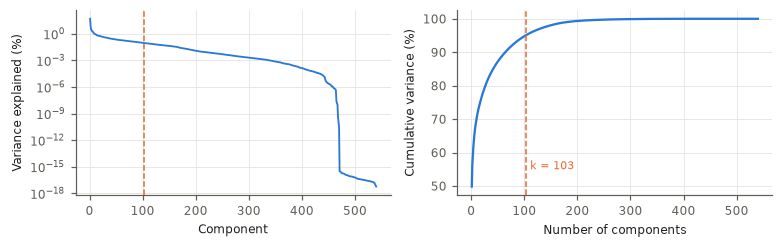

In [9]:
n = np.arange(1, len(evr) + 1)
fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE_W, 2.3))
axes[0].plot(n, evr * 100, color=ps.BLUE, lw=1.2)
axes[0].set_yscale("log")
axes[0].set_xlabel("Component"); axes[0].set_ylabel("Variance explained (%)")
axes[1].plot(n, cum * 100, color=ps.BLUE, lw=1.5)
axes[1].set_xlabel("Number of components"); axes[1].set_ylabel("Cumulative variance (%)")
for ax in axes:
    ax.axvline(k, color=ps.ORANGE, lw=1, ls="--")
axes[1].text(k + 8, 55, f"k = {k}", color=ps.ORANGE, fontsize=7)
fig.tight_layout()
save(fig, "pca_scree"); plt.show()

✍️ **Decision — k:** *(Fixed variance threshold, elbow in the scree plot, or treat k as a hyperparameter to tune with grouped CV on Nov 11–13? What does going from ~540 to k inputs do to one-vs-all logistic regression (parameters = 6 × (k + 1)) and to the collinearity problem from the correlation section of `01_eda`? What is lost: can a coefficient still be read as "this feature matters"?)*

## 7. What do the first components mean?

Loadings = the weights in each principal direction. Large |loading| = that feature drives the component.

In [10]:
feat = np.array(dedup.keep_)
rows = []
for j in range(3):
    w = pca.components_[j]
    for i in np.argsort(-np.abs(w))[:8]:
        rows.append({"PC": f"PC{j + 1} ({pca.explained_variance_ratio_[j]:.0%})", "feature": feat[i], "loading": round(w[i], 3)})
pd.DataFrame(rows).set_index(["PC", "feature"])

loading
PC        feature                            
PC1 (50%) fBodyAccJerk-sma()           -0.060
          tBodyAccJerk-sma()           -0.060
          fBodyGyro-sma()              -0.060
          fBodyAcc-sma()               -0.060
          tBodyAccJerkMag-mean()       -0.060
          fBodyBodyAccJerkMag-mean()   -0.060
          tBodyAccJerkMag-mad()        -0.060
          tBodyAccJerkMag-std()        -0.060
PC2 (7%)  fBodyAcc-meanFreq()-Z        -0.126
          tBodyGyroMag-arCoeff()1      -0.123
          tGravityAcc-arCoeff()-Z,1    -0.120
          tGravityAcc-arCoeff()-Z,2     0.120
          fBodyAccMag-meanFreq()       -0.119
          tBodyAccMag-arCoeff()1       -0.119
          tGravityAcc-arCoeff()-Z,3    -0.118
          tBodyGyroMag-arCoeff()2       0.115
PC3 (3%)  tGravityAcc-arCoeff()-X,1     0.112
          tGravityAcc-energy()-X        0.111
          tGravityAcc-entropy()-Y      -0.110
          tGravityAcc-energy()-Z       -0.110
          tGravityAcc-min()-X           0.109
          angle(X,gravityMean)         -0.109
          tGravityAcc-std()-X          -0.106
          tGravityAcc-mad()-X          -0.105

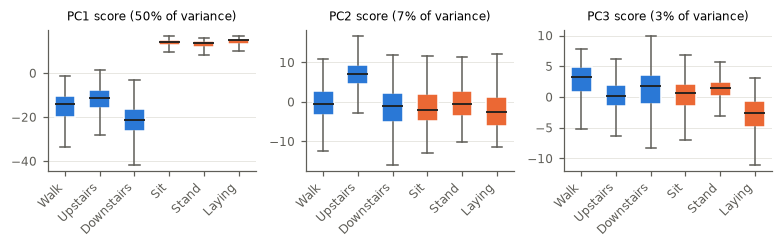

In [11]:
T_train = pca.transform(Z_train)
act = d.names(d.y_train).to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(ps.PAGE_W, 2.3))
for j, ax in enumerate(axes):
    bp = ax.boxplot([T_train[act == a, j] for a in ORDER], widths=0.6, patch_artist=True, showfliers=False,
                    medianprops=dict(color=ps.INK, lw=1.2),
                    whiskerprops=dict(color=ps.INK2), capprops=dict(color=ps.INK2))
    for a, box in zip(ORDER, bp["boxes"]):
        box.set(facecolor=ps.BLUE if a in DYNAMIC else ps.ORANGE, edgecolor="white", linewidth=1)
    ax.set_title(f"PC{j + 1} score ({pca.explained_variance_ratio_[j]:.0%} of variance)", fontsize=8)
    ax.set_xticks(range(1, 7), [ps.SHORT[a] for a in ORDER], rotation=45, ha="right")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "pc_scores_by_activity"); plt.show()

✍️ **Interpretation — components:** *(Which physical quantity does each of PC1–PC3 track: movement intensity, phone orientation, something else? Which activity pairs does none of the first three separate? Compare with the sit-vs-stand result in `01_eda`: the best sit/stand features were gravity-Y features. Do they load on an early or a late component, and what does that mean if I drop the late ones?)*

## 8. Apply to the test set

The scaler and PCA are applied as fitted; nothing is refit. Comparing the variance *not* captured on train vs. test is a quick check of whether directions learned from 21 subjects carry over to 9 new ones.

In [12]:
T_test = pca.transform(Z_test)
print("scores:", T_train.shape, T_test.shape)

def unexplained(Z, T):
    R = Z - pca.inverse_transform(T)
    return (R ** 2).sum() / ((Z - pca.mean_) ** 2).sum()

print(f"variance not captured by k = {k} components: "
      f"train {unexplained(Z_train, T_train):.1%} | test {unexplained(Z_test, T_test):.1%}")

scores: (7352, 103) (2947, 103)
variance not captured by k = 103 components: train 4.9% | test 6.5%


✍️ **Interpretation — test set:** *(Is the test reconstruction noticeably worse? If so, is that overfitting by PCA, or just new subjects moving differently?)*

## 9. The whole chain as one pipeline

Later notebooks rebuild the inputs from this one object instead of loading saved arrays, and the Nov 11–13 cross-validation refits it inside each fold.

In [13]:
from preprocess import make_prep

prep = make_prep(N_COMPONENTS, STANDARDIZE)
T_train_p = prep.fit_transform(d.X_train)
T_test_p = prep.transform(d.X_test)
assert np.allclose(np.abs(T_train_p), np.abs(T_train)) and np.allclose(np.abs(T_test_p), np.abs(T_test))
print("pipeline reproduces the step-by-step result ✓", T_train_p.shape, T_test_p.shape)

pipeline reproduces the step-by-step result ✓ (7352, 103) (2947, 103)


## 10. Summary of preprocessing decisions ✍️

*(3–5 bullets in my own words; these become the "Preprocessing" paragraph of the paper. Cover: cleaning (none needed, why); duplicate columns; scaling choice + train-only fit; k and how it was chosen; what the first components represent.)*

-
-
-

**Figures saved** (`figures/preprocessing/`): `pca_scree`, `pc_scores_by_activity` (each as .pdf and .png).